In [ ]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

# 1. Generar una señal (onda senoidal) de 1000 puntos
t = np.linspace(0, 50, 1000)
data = np.sin(t)

# 2. Crear las ventanas de tiempo (Time Steps = 10)
time_steps = 10
X, y = [], []

for i in range(len(data) - time_steps):
    X.append(data[i : i + time_steps]) # Los 10 pasos pasados
    y.append(data[i + time_steps])     # El paso siguiente (objetivo)

X = np.array(X)
y = np.array(y)

# 3. REDIMENSIONAR a las 3 dimensiones requeridas: (Lote, Pasos_Tiempo, Caracteristicas)
# Usamos nuestro truco del -1 para el Lote. Características = 1 (solo el valor del seno).
X = X.reshape((-1, time_steps, 1))

# Separar en Entrenamiento (80%) y Validación (20%)
# NOTA: En series temporales NO usamos shuffle aleatorio tradicional,
# ya que romperíamos la continuidad del tiempo. Separamos por bloques.
split = int(len(X) * 0.8)
X_train, X_val = X[:split], X[split:]
y_train, y_val = y[:split], y[split:]

print(f"Formato de X_train para la LSTM: {X_train.shape}") # Debería ser (792, 10, 1)


Formato de X_train para la LSTM: (792, 10, 1)


In [ ]:
model = keras.Sequential([
    keras.Input(shape=(time_steps, 1)),
    layers.LSTM(units=50, activation="tanh"),
    layers.Dense(units=1)
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam", loss="mse")

# Entrenamos la red
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_val, y_val)
)


Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.1200 - val_loss: 0.0459
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0298 - val_loss: 0.0285
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0251 - val_loss: 0.0240
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0221 - val_loss: 0.0217
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0192 - val_loss: 0.0176
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0161 - val_loss: 0.0147
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0121 - val_loss: 0.0106
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0076 - val_loss: 0.0056
Epoch 9/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0028 - val_loss: 0.0011
Epoch 10/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 4.5664e-04 - val_loss: 2.3696e-04
Epoch 11/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9129e-05 - val_loss: 3.5220e-05
Epoch 12/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


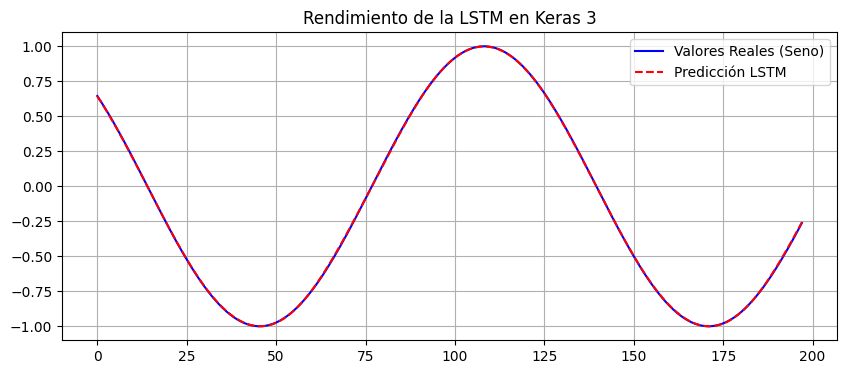

In [ ]:
# Hacer las predicciones
predicciones = model.predict(X_val)

# Graficar el resultado real vs la predicción de la LSTM
plt.figure(figsize=(10, 4))
plt.plot(y_val, label="Valores Reales (Seno)", color="blue")
plt.plot(predicciones, label="Predicción LSTM", color="red", linestyle="--")
plt.title("Rendimiento de la LSTM en Keras 3")
plt.legend()
plt.grid(True)
plt.show()
